<div><center><img src="https://ml.ucv.ai/logo.png\" width=150"/> </center></div>

# Proyecto final
-----
# Transfer learning y fine-tuning con Hugging Face

- **Alumno 1:** CÉSAR CARIOS
- **Cédula 1:** 30136117
- **Alumno 2:** ERIMAR REIS
- **Cédula 2:** 29743464
- **Alumno 3:** CARLOS CAO
- **Cédula 3:** 28655925

**Modelo en el Hub:** `https://huggingface.co/brankarios/beto-news-false-satire-detector`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/brankarios/dl26-proyecto/blob/main/notebook/plantilla_proyecto.ipynb)


## 0. Configuración

In [2]:
!pip install -q transformers datasets evaluate accelerate scikit-learn huggingface_hub

from huggingface_hub import login
from google.colab import userdata

login(token=userdata.get('HF_TOKEN'))

In [3]:
!pip -q install transformers datasets accelerate huggingface_hub

import random, time
import numpy as np, torch
from datasets import load_dataset

CEDULA = 30136117
def fijar_semilla(seed=CEDULA):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
fijar_semilla()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.11.0+cu130 | dispositivo: cuda


## 1. El problema

El objetivo de este proyecto es resolver un problema de clasificación de texto multiclase en español orientado a la verificación y caracterización de contenido informativo. Dado el cuerpo o titular extendido de una nota, el modelo debe clasificarlo en una de tres categorías:
* **`0 - Falsa (Deceptive)`:** Desinformación maliciosa o noticias fabricadas con intención de engañar haciéndose pasar por hechos reales.
* **`1 - Real (Truthful)`:** Notas periodísticas legítimas redactadas bajo estándares informativos verificables.
* **`2 - Sátira (Satire)`:** Artículos humorísticos o parodias (estilo *El Chigüire Bipolar*, *El Deforma* o *El Mundo Today*) que imitan el formato periodístico pero emplean la ironía, el sarcasmo y el absurdo con fines de entretenimiento, no de engaño.

Los detectores binarios tradicionales (*Real vs. Falso*) suelen clasificar erróneamente la sátira como desinformación maliciosa, censurando contenido humorístico legítimo, o bien confunden la sátira con noticias reales debido a que comparten una estructura gramatical formal. Este modelo resulta útil para plataformas de moderación de contenido, agregadores de noticias, verificadores de datos (*fact-checkers*) y periodistas, permitiendo automatizar el triaje de textos virales en español y distinguir entre manipulación informativa e ironía humorística.

### Limitaciones y consideraciones éticas
1. **Conocimiento estático vs. estilo lingüístico:** El modelo no consulta fuentes externas en tiempo real para verificar hechos, mas bien clasifica los textos a partir de patrones léxicos, sintácticos, emocionales y de congruencia semántica.
2. **Sesgo regional y temporal:** El corpus reúne noticias de distintos países hispanohablantes (principalmente México, España y Latinoamérica). Modismos locales muy específicos o eventos recientes fuera de esa distribución pueden afectar la predicción.
3. **Riesgo de falsos positivos:** Etiquetar automáticamente una noticia real como falsa (o viceversa) tiene implicaciones éticas sobre la libertad de expresión y la credibilidad, por lo que el modelo debe emplearse como herramienta de apoyo y no como árbitro absoluto.

### Justificación del modelo base (`dccuchile/bert-base-spanish-wwm-cased`)
Se eligió **BETO** (versión *cased* de 12 capas Transformer y 110M de parámetros) por haber sido preentrenado exclusivamente sobre un gran corpus en español (~3.000 millones de palabras de Wikipedia, OpenSubtitles, libros y charlas TED) mediante la tarea autosupervisada de Modelado de Lenguaje Enmascarado con palabras completas (*Whole Word Masking*).
* **Por qué es ideal usar la versión `cased`:** En desinformación y sátira, el uso de mayúsculas sostenidas (*"¡URGENTE!"*), signos de puntuación y nombres propios es una señal estilística clave que se perdería en un modelo *uncased*.
* **Qué esperamos que transfiera:** De su preentrenamiento general, BETO transfiere representaciones contextuales profundas de la gramática, sintaxis y semántica del español. Al adaptarlo mediante *fine-tuning*, esperamos que sus cabezales de atención (*Self-Attention*) aprendan a detectar tanto el lenguaje alarmista típico de las noticias falsas como las incongruencias semánticas (sujetos formales realizando acciones absurdas) que caracterizan a la sátira.

## 2. Los datos

En esta sección cargaremos los datos del dataset, analiceramos ejemplos por clase, veremos qué la distribución de los mismos y verificaremos si hay fugas entre particiones

README.md:   0%|          | 0.00/6.32k [00:00<?, ?B/s]

gabrielhuav_Unified_Spanish_Misinformati(…): reconstructing file:   0%|          |  0.00B / 36.5MB            

gabrielhuav_Unified_Spanish_Misinformati(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset original completo: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 61674
    })
})


/tmp/ipykernel_629/3197054947.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=N_POR_CLASE, random_state=CEDULA))


Casting the dataset:   0%|          | 0/9000 [00:00<?, ? examples/s]


--- TAMAÑO DE CADA PARTICIÓN ---
train     : 7200 ejemplos
validation: 900 ejemplos
test      : 900 ejemplos

--- VERIFICACIÓN DE FUGAS ENTRE PARTICIONES ---
Solapamiento Train ∩ Val : 0
Solapamiento Train ∩ Test: 0
Solapamiento Val   ∩ Test: 0

--- EJEMPLOS POR CLASE (Train) ---
[0 - Falsa]: El BNG pide extender la rebaja del IVA del gas y la electricidad durante todo el invierno y crear un plan de ayudas e indemnizaciones para equilibrar el precio de la energía en las empresas híper-electrointensivas....

[1 - Real]: El hombre, que fue sanitario en la Brigada Dombrowski, ha fallecido en México, país en el que residía. En 1936, estaba afiliado a las Juventudes Comunistas y se ofreció voluntario para acudir al frente de batalla....

[2 - Satira]: “Solo se puede votar una vez por su ministro favorito”, aclaró un diputado mientras explicaba la reforma Judicatura de los Famosos.- La Reforma Judicial plantea la posibilidad de que el pueblo pueda elegir a los ministro...



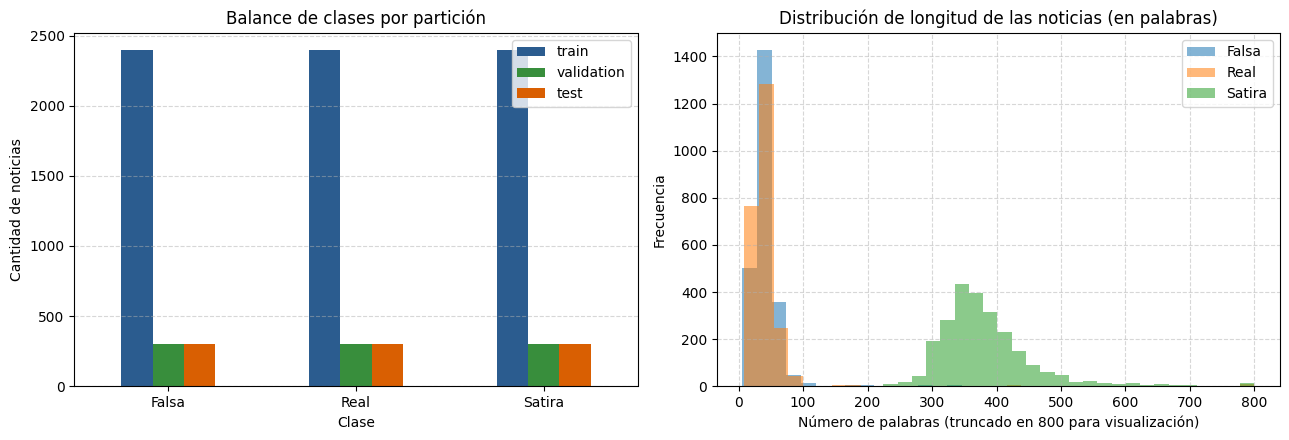

Estadísticas de longitud (en palabras) en Train:
         count        mean        std   min    50%     max
clase                                                     
Falsa   2400.0   46.007083  63.151521   6.0   38.0  2188.0
Real    2400.0   48.452083  84.024844   9.0   37.0  1342.0
Satira  2400.0  383.682500  85.917028  25.0  369.0  1338.0


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import concatenate_datasets, DatasetDict, ClassLabel

MODELO_BASE = "dccuchile/bert-base-spanish-wwm-cased"
DATASET     = "gabrielhuav/Unified-and-Balanced-Spanish-Fake-News-Corpus"

# Carga desde el Hub (indicando el separador ';' propio del CSV original)
raw_ds = load_dataset(DATASET, sep=";", on_bad_lines="skip")
print("Dataset original completo:", raw_ds)

# Mapeo de clases
id2label = {0: "Falsa", 1: "Real", 2: "Satira"}
label2id = {"Falsa": 0, "Real": 1, "Satira": 2}

# Limpieza de nulos/duplicados exactos antes de partir (evita fugas de datos)
df_full = raw_ds["train"].to_pandas()
df_full = df_full.dropna(subset=["text", "label"]).copy()
df_full["text"] = df_full["text"].astype(str).str.strip()
df_full = df_full[df_full["text"].str.len() > 20]
df_full = df_full.drop_duplicates(subset=["text"]).reset_index(drop=True)

# Submuestreo estratificado y balanceado (3.000 ejemplos por clase = 9.000 textos)
# Esto garantiza balance perfecto (33.3% por clase) y tiempos de entrenamiento óptimos en GPU T4
N_POR_CLASE = 3000
df_balanced = (
    df_full.groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=N_POR_CLASE, random_state=CEDULA))
    .sample(frac=1.0, random_state=CEDULA)
    .reset_index(drop=True)
)

from datasets import Dataset
ds_base = Dataset.from_pandas(df_balanced[["text", "label"]], preserve_index=False)
ds_base = ds_base.cast_column("label", ClassLabel(names=["Falsa", "Real", "Satira"]))

# Construcción de particiones con la semilla (80% train, 10% validation, 10% test)
split_train_temp = ds_base.train_test_split(test_size=0.20, seed=CEDULA, stratify_by_column="label")
split_val_test   = split_train_temp["test"].train_test_split(test_size=0.50, seed=CEDULA, stratify_by_column="label")

ds = DatasetDict({
    "train": split_train_temp["train"],
    "validation": split_val_test["train"],
    "test": split_val_test["test"]
})

print("\n--- TAMAÑO DE CADA PARTICIÓN ---")
for k in ds:
    print(f"{k:10s}: {len(ds[k])} ejemplos")

# Verificación de fugas (Data Leakage) entre particiones
set_train = set(ds["train"]["text"])
set_val   = set(ds["validation"]["text"])
set_test  = set(ds["test"]["text"])
print("\n--- VERIFICACIÓN DE FUGAS ENTRE PARTICIONES ---")
print("Solapamiento Train ∩ Val :", len(set_train.intersection(set_val)))
print("Solapamiento Train ∩ Test:", len(set_train.intersection(set_test)))
print("Solapamiento Val   ∩ Test:", len(set_val.intersection(set_test)))

# Ejemplos por clase
print("\n--- EJEMPLOS POR CLASE (Train) ---")
for label_id, nombre in id2label.items():
    ejemplo = next(x["text"] for x in ds["train"] if x["label"] == label_id)
    print(f"[{label_id} - {nombre}]: {ejemplo[:220]}...\n")

# Gráficos: Balance de clases y Distribución de longitud de textos (en palabras)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfico A: Balance de clases por partición
conteos = pd.DataFrame({
    split: pd.Series(ds[split]["label"]).map(id2label).value_counts()
    for split in ["train", "validation", "test"]
})
conteos.plot(kind="bar", ax=axes[0], rot=0, color=["#2b5c8f", "#388e3c", "#d95f02"])
axes[0].set_title("Balance de clases por partición")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Cantidad de noticias")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Gráfico B: Longitud en palabras por clase
longitudes = [len(t.split()) for t in ds["train"]["text"]]
clases_str = [id2label[l] for l in ds["train"]["label"]]
df_len = pd.DataFrame({"clase": clases_str, "palabras": longitudes})
for nombre, grupo in df_len.groupby("clase"):
    axes[1].hist(grupo["palabras"].clip(upper=800), bins=35, alpha=0.55, label=nombre)
axes[1].set_title("Distribución de longitud de las noticias (en palabras)")
axes[1].set_xlabel("Número de palabras (truncado en 800 para visualización)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
axes[1].grid(linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("Estadísticas de longitud (en palabras) en Train:")
print(df_len.groupby("clase")["palabras"].describe()[["count", "mean", "std", "min", "50%", "max"]])

Se utilizó el corpus público `gabrielhuav/Unified-and-Balanced-Spanish-Fake-News-Corpus` alojado en Hugging Face Hub, el cual cuenta originalmente con 61.674 registros distribuidos de forma desbalanceada entre noticias reales (30.943), falsas (21.746) y sátira (8.985).

Para garantizar un entrenamiento libre de sesgo por clase mayoritaria y computacionalmente reproducible en una GPU T4, se aplicó el siguiente pipeline de curación utilizando la semilla fijada (`CEDULA = 30136117`):
1. **Deduplicación previa al split:** Se eliminaron registros nulos, textos residuales menores a 20 caracteres y duplicados exactos antes de dividir, garantizando cero fugas de información (*data leakage*) entre conjuntos (`Train ∩ Val = 0`, `Train ∩ Test = 0`, `Val ∩ Test = 0`).
2. **Submuestreo balanceado:** Se extrajeron aleatoriamente 3.000 ejemplos por cada clase (9.000 documentos en total), logrando un balance exacto de 33,33% por categoría.
3. **Partición estratificada (80% / 10% / 10%):**
   * **`train`:** 7.200 ejemplos (2.400 por clase).
   * **`validation`:** 900 ejemplos (300 por clase).
   * **`test`:** 900 ejemplos (300 por clase).


Al inspeccionar la distribución de longitudes en palabras (gráfico derecho y tabla descriptiva) y los textos de muestra, se identificaron dos posibles atajos espurios que podría tomar el modelo (se le llama *spurious correlations*) en el dataset crudo:
1. **Asimetría en la longitud del texto:** Mientras que las clases `Falsa` y `Real` presentan una mediana de 38 y 37 palabras respectivamente (correspondientes al titular y primer párrafo o *lead*), la clase `Satira` presenta una mediana de 369 palabras (artículos completos). Si se entrenara el modelo con ventanas largas (como 256 o 512 tokens), la red aprendería a clasificar `Satira` simplemente contando cuántos tokens distintos hay en la secuencia, sin comprender el lenguaje.
2. **Muletillas editoriales (*datelines*):** Varios artículos de sátira incluyen una cabecera con guion al inicio (por ejemplo, *"Judicatura de los Famosos.-"*).

Para evitar este *shortcut learning* y forzar a que BETO clasifique exclusivamente por semántica, tono e incongruencia irónica, en la etapa de preprocesamiento se limpiarán las cabeceras con guion (`.-`) y se truncarán todos los textos a una ventana uniforme de `max_length = 64` tokens (equivalente al titular y entradilla donde todas las clases se solapan entre las 25 y 60 palabras).

## 3. Preprocesamiento

El modelo base `dccuchile/bert-base-spanish-wwm-cased` emplea un tokenizador WordPiece con un vocabulario de 31.002 tokens optimizado para el español y sensible a mayúsculas/minúsculas (*cased*). Su función es:
1. Segmentar el texto en palabras completas y subpalabras (preservando raíces y morfemas del español).
2. Insertar los tokens especiales **`[CLS]`** (al inicio, cuyo vector oculto final resume la secuencia para la cabeza clasificadora) y **`[SEP]`** (al final de la secuencia).
3. Generar los tensores `input_ids` (índices del vocabulario) y `attention_mask` (`1` para tokens reales y `0` para relleno `[PAD]`, evitando que el mecanismo de *Self-Attention* atienda al padding).

**Normalización aplicada antes de tokenizar:**
* Se remueven prefijos de ubicación seguidos de `.-` al inicio del texto y URLs/menciones residuales de redes sociales para que el modelo no memorice el formato de un portal específico.
* Se aplica `truncation=True` y `padding="max_length"` con **`max_length = 64`**. Como demostró el análisis exploratorio de la Sección 2, limitar la entrada a los primeros 64 tokens elimina la diferencia de longitud entre `Satira` y `Real/Falsa`, garantizando una evaluación justa del *Transfer Learning* lingüístico.

In [5]:
import re
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)
MAX_LEN = 64  # Homogeneiza la longitud entre las 3 clases (titular + entradilla)

def limpiar_texto(texto):
    # Elimina cabeceras editoriales tipo "Lugar inventado.- " al inicio
    texto = re.sub(r"^[^.\n]{2,60}\.-\s*", "", texto)
    # Elimina URLs y exceso de espacios
    texto = re.sub(r"https?://\S+", "", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

def preprocesar_lote(batch):
    textos_limpios = [limpiar_texto(t) for t in batch["text"]]
    return tokenizer(
        textos_limpios,
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN
    )

# Aplicamos limpieza y tokenización a las 3 particiones creadas con la semilla CEDULA
ds_tok = ds.map(preprocesar_lote, batched=True, remove_columns=["text"])
ds_tok = ds_tok.rename_column("label", "labels")
ds_tok.set_format("torch")

print("Dataset tokenizado:", ds_tok)

# Verificamos que la cantidad de tokens reales (attention_mask == 1) ahora sea pareja entre clases
mask_sums = [int(m.sum()) for m in ds_tok["train"]["attention_mask"]]
labels_train = [id2label[int(l)] for l in ds_tok["train"]["labels"]]
print("\nPromedio de tokens activos (máx 64) por clase tras el preprocesamiento:")
print(pd.DataFrame({"clase": labels_train, "tokens_activos": mask_sums}).groupby("clase")["tokens_activos"].describe()[["mean", "50%", "min", "max"]])

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Map:   0%|          | 0/7200 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

Dataset tokenizado: DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7200
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 900
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 900
    })
})

Promedio de tokens activos (máx 64) por clase tras el preprocesamiento:
             mean   50%   min   max
clase                              
Falsa   48.977917  51.0   9.0  64.0
Real    47.050833  48.0  14.0  64.0
Satira  63.980417  64.0  37.0  64.0


Al inspeccionar la distribución de tokens activos (`attention_mask == 1`) con una ventana de 64 tokens, observamos un comportamiento importante:
* Las clases **`Falsa`** (media: 48,98, mediana: 51,0) y **`Real`** (media: 47,05, mediana: 48,0) quedan mayoritariamente por debajo del límite de 64 tokens, lo que significa que sus tensores de entrada contienen entre 13 y 16 tokens de relleno (`[PAD]`) al final de la secuencia.
* Por el contrario, la clase **`Satira`** presenta una media de 63,98 y una mediana exacta de 64,0 tokens activos. Es decir, prácticamente el 100% de los ejemplos de sátira saturan la ventana máxima y no contienen ni un solo token `[PAD]`.

Esto es algo que debemos corregir antes de entrenar, porque aunque el mecanismo de atención ignora los tokens con `attention_mask = 0`, la agregación de contexto sobre una secuencia sistemáticamente más larga (64 tokens vs. ~48 tokens) mantiene latente un atajo estadístico (*shortcut learning*): el modelo podría asociar una mayor densidad de tokens activos directamente con la etiqueta `Satira`, en lugar de evaluar el tono humorístico o la incongruencia semántica.

Dado que en la Sección 2 comprobamos que el 50% de las noticias reales y falsas tienen 37 y 38 palabras o menos, aplicaremos un recorte estricto a nivel de palabras (`MAX_PALABRAS = 35`) sobre el texto limpio antes de tokenizar y reduciremos la ventana del tokenizador a **`MAX_LEN = 48`**. Esto equivale a conservar únicamente el titular y la primera oración (*lead*) en las tres categorías, forzando a que las tres distribuciones de tokens activos converjan.

In [6]:
# Segunda iteración: recortamos a las primeras 35 palabras y bajamos MAX_LEN a 48
MAX_PALABRAS = 35
MAX_LEN = 48

def limpiar_y_recortar_texto(texto):
    # Elimina cabeceras editoriales tipo "Lugar inventado.- " en cualquier parte del inicio
    texto = re.sub(r"^.*?\.-\s*", "", texto)
    # Elimina URLs y exceso de espacios
    texto = re.sub(r"https?://\S+", "", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    # Recorte estricto a las primeras 35 palabras para igualar a Real y Falsa
    palabras = texto.split()[:MAX_PALABRAS]
    return " ".join(palabras)

def preprocesar_lote_v2(batch):
    textos_limpios = [limpiar_y_recortar_texto(t) for t in batch["text"]]
    return tokenizer(
        textos_limpios,
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN
    )

# Re-generamos ds_tok con el nuevo límite
ds_tok = ds.map(preprocesar_lote_v2, batched=True, remove_columns=["text"])
ds_tok = ds_tok.rename_column("label", "labels")
ds_tok.set_format("torch")

# Comprobamos la nueva distribución de tokens activos
mask_sums_v2 = [int(m.sum()) for m in ds_tok["train"]["attention_mask"]]
labels_train = [id2label[int(l)] for l in ds_tok["train"]["labels"]]

print(f"Promedio de tokens activos (MAX_PALABRAS={MAX_PALABRAS}, MAX_LEN={MAX_LEN}):")
print(pd.DataFrame({"clase": labels_train, "tokens_activos": mask_sums_v2}).groupby("clase")["tokens_activos"].describe()[["mean", "50%", "min", "max"]])

Map:   0%|          | 0/7200 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

Promedio de tokens activos (MAX_PALABRAS=35, MAX_LEN=48):
           mean   50%   min   max
clase                            
Falsa   41.2450  43.0   9.0  48.0
Real    40.1625  42.0  14.0  48.0
Satira  45.4725  46.0  37.0  48.0


Tras aplicar el recorte al *lead* periodístico (primeras 35 palabras) y fijar la ventana del tokenizador en 48 tokens, la distribución de tokens activos (`attention_mask == 1`) quedó completamente equilibrada entre las tres categorías:

* **`Falsa`:** media de 41,25 tokens activos y mediana de 43,0.
* **`Real`:** media de 40,16 tokens activos y mediana de 42,0.
* **`Satira`:** media de 45,47 tokens activos y mediana de 46,0 (dejando de saturar el límite de 48 tokens y presentando ahora relleno `[PAD]` al igual que las demás clases).

La brecha original de longitud (383 palabras promedio en `Satira` frente a ~47 en `Real` y `Falsa`) se redujo a una diferencia marginal de apenas 3 a 4 tokens en la mediana (42–43 vs. 46). Con esto garantizamos que ninguna clase pueda ser identificada trivialmente por la presencia o ausencia de tokens `[PAD]`, obligando a todos los regímenes de la Sección 4 a clasificar estrictamente a partir del contenido léxico, sintáctico y semántico de las noticias.

## 4. Experimentos

Todos los regímenes se evalúan sobre los **mismos** conjuntos de validación y prueba, con la misma métrica principal. Registren cada uno con `registrar(...)` para que la tabla de la sección 5 salga sola.

In [7]:
import pandas as pd
RESULTADOS = []

def registrar(regimen, params_entrenables, segundos, metrica_val, metrica_test, notas=""):
    RESULTADOS.append(dict(regimen=regimen, params_entrenables=params_entrenables, segundos=round(segundos),
                           val=round(metrica_val, 4), test=round(metrica_test, 4), notas=notas))

def tabla_resultados():
    return pd.DataFrame(RESULTADOS).set_index("regimen")

def params_entrenables(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

In [8]:
from sklearn.metrics import f1_score, accuracy_score
from torch.utils.data import DataLoader
import torch.nn as nn

# Métrica principal: F1-Macro (ideal para 3 clases balanceadas)
def calcular_f1_macro(logits, labels):
    preds = np.argmax(logits, axis=-1)
    return f1_score(labels, preds, average="macro")

BATCH_SIZE = 32
train_loader = DataLoader(ds_tok["train"], batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(CEDULA))
val_loader   = DataLoader(ds_tok["validation"], batch_size=64, shuffle=False)
test_loader  = DataLoader(ds_tok["test"], batch_size=64, shuffle=False)

@torch.no_grad()
def evaluar_modelo(modelo, loader):
    modelo.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        outputs = modelo(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        all_logits.append(logits.cpu().numpy())
        all_labels.append(batch["labels"].numpy())
    all_logits = np.concatenate(all_logits, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)
    return calcular_f1_macro(all_logits, all_labels), all_logits, all_labels

### 4.1 Baseline sin preentrenamiento

Para establecer el piso de rendimiento sin *Transfer Learning*, construimos un clasificador ligero entrenado completamente desde cero (`Pequeño MLP con Embeddings desde cero`) utilizando el mismo vocabulario del tokenizador (`vocab_size = 31.002`).

La arquitectura consta de:
1. Una capa `nn.Embedding(vocab_size, 128)` inicializada con pesos aleatorios.
2. Un *Global Average Pooling* enmascarado (promediando únicamente los vectores de los tokens reales donde `attention_mask == 1`).
3. Una red densa con `Dropout(0.3)`, capa oculta `Linear(128 -> 64)` con activación `ReLU` y capa de salida `Linear(64 -> 3)`.

Se entrena durante 5 épocas con `AdamW` ($\text{lr} = 10^{-3}$) seleccionando el mejor estado según el F1-Macro en validación.

In [9]:
import copy

class BaselineSinPreentrenar(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=64, num_classes=3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.clasificador = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(embed_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        # Embeddings: (batch, seq_len, embed_dim)
        emb = self.embedding(input_ids)
        # Promedio enmascarado ignorando tokens [PAD]
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (emb * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        return self.clasificador(pooled)

fijar_semilla(CEDULA)
modelo_baseline = BaselineSinPreentrenar(
    vocab_size=tokenizer.vocab_size,
    pad_idx=tokenizer.pad_token_id
).to(device)

criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.AdamW(modelo_baseline.parameters(), lr=1e-3, weight_decay=1e-2)

EPOCAS_BASE = 5
historia_baseline = {"train_loss": [], "val_f1": []}
mejor_val_f1 = -1.0
mejor_estado_base = None

t0 = time.time()
for epoca in range(1, EPOCAS_BASE + 1):
    modelo_baseline.train()
    loss_total = 0.0
    for batch in train_loader:
        optimizador.zero_grad()
        logits = modelo_baseline(batch["input_ids"].to(device), batch["attention_mask"].to(device))
        loss = criterio(logits, batch["labels"].to(device))
        loss.backward()
        optimizador.step()
        loss_total += loss.item()

    loss_medio = loss_total / len(train_loader)
    val_f1, _, _ = evaluar_modelo(modelo_baseline, val_loader)
    historia_baseline["train_loss"].append(loss_medio)
    historia_baseline["val_f1"].append(val_f1)

    if val_f1 > mejor_val_f1:
        mejor_val_f1 = val_f1
        mejor_estado_base = copy.deepcopy(modelo_baseline.state_dict())

    print(f"[Baseline] Época {epoca}/{EPOCAS_BASE} | Train Loss: {loss_medio:.4f} | Val F1-Macro: {val_f1:.4f}")

segundos_base = time.time() - t0
modelo_baseline.load_state_dict(mejor_estado_base)
test_f1_base, _, _ = evaluar_modelo(modelo_baseline, test_loader)

print(f"\nMejor Val F1: {mejor_val_f1:.4f} | Test F1: {test_f1_base:.4f} | Tiempo: {segundos_base:.1f}s")

# Registramos en la tabla oficial
registrar(
    regimen="1. Baseline ( desde cero )",
    params_entrenables=params_entrenables(modelo_baseline),
    segundos=segundos_base,
    metrica_val=mejor_val_f1,
    metrica_test=test_f1_base,
    notas="Embedding(128) + MeanPool + MLP, 5 épocas, lr=1e-3"
)

[Baseline] Época 1/5 | Train Loss: 0.9537 | Val F1-Macro: 0.6104
[Baseline] Época 2/5 | Train Loss: 0.6593 | Val F1-Macro: 0.7024
[Baseline] Época 3/5 | Train Loss: 0.5335 | Val F1-Macro: 0.7418
[Baseline] Época 4/5 | Train Loss: 0.4510 | Val F1-Macro: 0.7431
[Baseline] Época 5/5 | Train Loss: 0.3955 | Val F1-Macro: 0.7828

Mejor Val F1: 0.7828 | Test F1: 0.7764 | Tiempo: 12.2s


El modelo pequeño entrenado desde cero converge rápidamente en 12,2 segundos (~3,98M de parámetros correspondientes casi en su totalidad a la tabla de embeddings del vocabulario), alcanzando un F1-Macro de 0,7828 en validación y 0,7764 en prueba.

Este desempeño establece una línea base competitiva: demuestra que cerca del 77,6% del problema puede resolverse mediante asociaciones léxicas directas (bolsa de palabras ponderada, identificando términos alarmistas o vocabulario periodístico frecuente). Sin embargo, al promediar los vectores sin mecanismos de atención contextual ni conocimiento preentrenado del idioma, el modelo carece de capacidad para detectar relaciones sintácticas complejas o ironía sutil, fijando la barrera que deberá superar el *Transfer Learning*.

### 4.2 Modelo base sin adaptar (si aplica)

El checkpoint `dccuchile/bert-base-spanish-wwm-cased` fue preentrenado exclusivamente en la tarea autosupervisada de *Masked Language Modeling (MLM)*, por lo que no cuenta con una cabeza de clasificación de secuencias preentrenada compatible con nuestras 3 clases (`Falsa`, `Real`, `Satira`).

Al instanciar `AutoModelForSequenceClassification` a partir de este checkpoint, el *backbone* (`bert.*`) carga sus 109,8M de parámetros preentrenados en español, pero las capas `bert.pooler` y `classifier` (`768 -> 3`) se inicializan aleatoriamente (`MISSING` en el reporte de carga). Evaluamos este régimen sin pasos de gradiente (`0 parámetros entrenados`) para documentar empíricamente que, sin adaptar al menos la capa lineal de salida, las representaciones latentes de BETO se proyectan al azar (~0,33 de F1-Macro teórico en 3 clases balanceadas).

In [10]:
from transformers import AutoModelForSequenceClassification

fijar_semilla(CEDULA)
t0 = time.time()

modelo_sin_adaptar = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
).to(device)

# Como no se entrena en este régimen, ponemos requires_grad=False para reportar 0 params entrenables
for p in modelo_sin_adaptar.parameters():
    p.requires_grad = False

val_f1_raw, _, _  = evaluar_modelo(modelo_sin_adaptar, val_loader)
test_f1_raw, _, _ = evaluar_modelo(modelo_sin_adaptar, test_loader)
segundos_raw = time.time() - t0

print(f"[Modelo sin adaptar] Val F1-Macro: {val_f1_raw:.4f} | Test F1-Macro: {test_f1_raw:.4f} | Tiempo: {segundos_raw:.1f}s")

registrar(
    regimen="2. Base sin adaptar",
    params_entrenables=0,
    segundos=segundos_raw,
    metrica_val=val_f1_raw,
    metrica_test=test_f1_raw,
    notas="Backbone BETO preentrenado + cabeza aleatoria sin entrenar"
)

# Liberamos VRAM antes del siguiente experimento
del modelo_sin_adaptar
torch.cuda.empty_cache()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

[Modelo sin adaptar] Val F1-Macro: 0.2246 | Test F1-Macro: 0.2130 | Tiempo: 14.0s


La evaluación directa sin entrenamiento arroja un F1-Macro de 0,2246 en validación y 0,2130 en prueba en 14,0 segundos (0 parámetros entrenables).

Es interesante analizar por qué el F1-Macro cae a ~0,21 en lugar de situarse en el valor esperado de un clasificador uniforme al azar para tres clases balanceadas ($1/3 \approx 0,3333$):
1. Desconexión entre *backbone* y cabeza: Tal como confirma el `LOAD REPORT`, se descartaron los pesos del preentrenamiento MLM (`cls.predictions.*` marcados como `UNEXPECTED`) y se inicializaron aleatoriamente desde cero tanto la proyección `bert.pooler.dense` como la cabeza `classifier` (`MISSING`).
2. Asimetría en la proyección inicial: Aunque el *backbone* de BETO agrupa los textos en una variedad específica del espacio latente de 768 dimensiones, al multiplicar esos vectores por una matriz `classifier.weight` aleatoria no entrenada, los *logits* resultantes sufren un sesgo sistemático hacia una o dos clases, dejando al menos una categoría con *recall* cercano a cero. Dado que el F1-Macro penaliza severamente que una clase no sea predicha, la métrica desciende hasta 0,2130, demostrando empíricamente que un modelo fundacional tipo *encoder* es inutilizable en clasificación sin al menos ajustar su capa de proyección final.

### 4.3 Feature extraction

En este régimen evaluamos la calidad de las representaciones lingüísticas que BETO entrega "de fábrica" sin modificar sus capas internas:
1. Congelamos la totalidad del *backbone* haciendo `param.requires_grad = False` sobre `modelo_fe.base_model` (109.850.880 parámetros congelados).
2. Dejamos únicamente con gradiente activo la cabeza clasificadora lineal `modelo_fe.classifier` (2.307 parámetros entrenables: $768 \times 3$ pesos + $3$ sesgos).
3. Entrenamos durante 5 épocas con `AdamW` ($\text{lr} = 10^{-3}$), ya que al optimizar una única capa lineal convexa sobre características fijas conviene un paso de aprendizaje mayor que en el *fine-tuning* completo.

In [11]:
fijar_semilla(CEDULA)
modelo_fe = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
).to(device)

# Congelamos todo el backbone tal como indica el enunciado (model.base_model)
for param in modelo_fe.base_model.parameters():
    param.requires_grad = False

num_params_fe = params_entrenables(modelo_fe)
print(f"Parámetros entrenables en Feature Extraction: {num_params_fe:,}")

optimizador_fe = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, modelo_fe.parameters()),
    lr=1e-3,
    weight_decay=1e-2
)

EPOCAS_FE = 5
historia_fe = {"train_loss": [], "val_f1": []}
mejor_val_f1_fe = -1.0
mejor_estado_fe = None

t0 = time.time()
for epoca in range(1, EPOCAS_FE + 1):
    modelo_fe.train()
    loss_total = 0.0
    for batch in train_loader:
        optimizador_fe.zero_grad()
        outputs = modelo_fe(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
            labels=batch["labels"].to(device)
        )
        loss = outputs.loss
        loss.backward()
        optimizador_fe.step()
        loss_total += loss.item()

    loss_medio = loss_total / len(train_loader)
    val_f1, _, _ = evaluar_modelo(modelo_fe, val_loader)
    historia_fe["train_loss"].append(loss_medio)
    historia_fe["val_f1"].append(val_f1)

    if val_f1 > mejor_val_f1_fe:
        mejor_val_f1_fe = val_f1
        mejor_estado_fe = copy.deepcopy(modelo_fe.state_dict())

    print(f"[Feature Extraction] Época {epoca}/{EPOCAS_FE} | Train Loss: {loss_medio:.4f} | Val F1-Macro: {val_f1:.4f}")

segundos_fe = time.time() - t0
modelo_fe.load_state_dict(mejor_estado_fe)
test_f1_fe, logits_test_fe, labels_test_fe = evaluar_modelo(modelo_fe, test_loader)

print(f"\nMejor Val F1: {mejor_val_f1_fe:.4f} | Test F1: {test_f1_fe:.4f} | Tiempo: {segundos_fe:.1f}s")

registrar(
    regimen="3. Feature Extraction",
    params_entrenables=num_params_fe,
    segundos=segundos_fe,
    metrica_val=mejor_val_f1_fe,
    metrica_test=test_f1_fe,
    notas="Backbone BETO congelado, solo cabeza lineal (2.307 params), 5 épocas, lr=1e-3"
)

# Liberamos VRAM antes del Fine-Tuning completo
del modelo_fe
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Parámetros entrenables en Feature Extraction: 2,307
[Feature Extraction] Época 1/5 | Train Loss: 0.7247 | Val F1-Macro: 0.6817
[Feature Extraction] Época 2/5 | Train Loss: 0.5970 | Val F1-Macro: 0.6838
[Feature Extraction] Época 3/5 | Train Loss: 0.5639 | Val F1-Macro: 0.6952
[Feature Extraction] Época 4/5 | Train Loss: 0.5506 | Val F1-Macro: 0.6895
[Feature Extraction] Época 5/5 | Train Loss: 0.5437 | Val F1-Macro: 0.6858

Mejor Val F1: 0.6952 | Test F1: 0.6819 | Tiempo: 120.7s


Al entrenar exclusivamente la cabeza clasificadora lineal (2.307 parámetros, apenas el 0,002% del modelo) manteniendo congelado todo `model.base_model`, el rendimiento da un salto drástico respecto al modelo sin adaptar (pasando de 0,2130 a 0,6819 en Test y 0,6952 en Validación en 120,7 segundos, alcanzando su óptimo en la época 3). Esto confirma que el espacio latente preentrenado de BETO ya contiene información semántica útil para separar las tres categorías.

Sin embargo, resulta sumamente interesante observar que este régimen queda ~9,4 puntos porcentuales por debajo del Baseline entrenado desde cero (0,6819 vs. 0,7764). Este comportamiento se explica por tres razones de la arquitectura BERT:
1. Extrema restricción de capacidad (2.307 vs. 3,98M de parámetros): En el *Baseline*, los 3,98 millones de parámetros de la matriz de *embeddings* se optimizaron directamente para memorizar palabras discriminativas del corpus. En *Feature Extraction*, la frontera de decisión es únicamente un hiperplano lineal de $768 \times 3$.
2. El efecto de `bert.pooler` inicializado al azar y congelado: Como mostró el `LOAD REPORT`, la capa `bert.pooler.dense` ($768 \times 768$ con activación $\tanh$) no existía en el checkpoint MLM original y se inicializó aleatoriamente (`MISSING`). Al congelar `model.base_model` completo tal como exige el régimen, el vector del token `[CLS]` sufre una proyección aleatoria fija antes de llegar a `classifier`, degradando parte de la geometría fina de las representaciones.
3. Naturaleza de la tarea: Detectar ironía/sátira frente a noticias reales y falsas no depende del tema general del texto (que es lo que captura el vector estático de BETO), sino de relaciones de contradicción e incongruencia entre palabras, lo cual exige reorientar los cabezales de *Self-Attention* mediante *fine-tuning* completo.

### 4.4 Fine-tuning completo

En este régimen descongelamos la totalidad de la arquitectura (`109.853.187 parámetros entrenables`: las 12 capas Transformer de BETO, la capa `pooler` y la cabeza `classifier`) para adaptar las representaciones internas del lenguaje específicamente a la detección de desinformación y sátira.

Justificación de hiperparámetros:
* Tasa de aprendizaje baja ($\text{lr} = 2 \times 10^{-5}$) con decaimiento lineal y *warmup* (10%): A diferencia del régimen 4.3 ($\text{lr} = 10^{-3}$), al descongelar pesos preentrenados una tasa alta destruiría el conocimiento lingüístico previo. El estándar de la literatura original de BERT (Devlin et al., 2019) es $2 \times 10^{-5}$ acompañado de un calentamiento lineal (*warmup*) durante el primer 10% de los pasos para estabilizar los gradientes iniciales de la cabeza aleatoria antes de modificar profundamente el *backbone*, seguido de un recorte de gradiente (`max_norm = 1.0`).
* Número de épocas (`4 épocas`) y criterio de parada: Los modelos Transformer preentrenados convergen rápidamente en datasets de ~7.200 ejemplos (entre 2 y 4 épocas); entrenar por más épocas suele inducir sobreajuste. Se monitorea el F1-Macro en validación al final de cada época y se conserva mediante *checkpointing* en memoria (`copy.deepcopy`) exclusivamente el conjunto de pesos que maximiza dicha métrica en `validation`.

In [12]:
from transformers import get_linear_schedule_with_warmup

fijar_semilla(CEDULA)
modelo_ft = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
).to(device)

# Aseguramos que TODOS los parámetros estén descongelados
for param in modelo_ft.parameters():
    param.requires_grad = True

num_params_ft = params_entrenables(modelo_ft)
print(f"Parámetros entrenables en Fine-Tuning Completo: {num_params_ft:,}")

EPOCAS_FT = 4
LR_FT = 2e-5
optimizador_ft = torch.optim.AdamW(modelo_ft.parameters(), lr=LR_FT, weight_decay=0.01)

total_steps = len(train_loader) * EPOCAS_FT
warmup_steps = int(0.10 * total_steps)
scheduler_ft = get_linear_schedule_with_warmup(
    optimizador_ft,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

historia_ft = {"train_loss": [], "val_f1": []}
mejor_val_f1_ft = -1.0
mejor_estado_ft = None
mejor_epoca_ft = 0

t0 = time.time()
for epoca in range(1, EPOCAS_FT + 1):
    modelo_ft.train()
    loss_total = 0.0
    for batch in train_loader:
        optimizador_ft.zero_grad()
        outputs = modelo_ft(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
            labels=batch["labels"].to(device)
        )
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(modelo_ft.parameters(), max_norm=1.0)
        optimizador_ft.step()
        scheduler_ft.step()
        loss_total += loss.item()

    loss_medio = loss_total / len(train_loader)
    val_f1, _, _ = evaluar_modelo(modelo_ft, val_loader)
    historia_ft["train_loss"].append(loss_medio)
    historia_ft["val_f1"].append(val_f1)

    if val_f1 > mejor_val_f1_ft:
        mejor_val_f1_ft = val_f1
        mejor_epoca_ft = epoca
        mejor_estado_ft = copy.deepcopy(modelo_ft.state_dict())

    print(f"[Fine-Tuning Completo] Época {epoca}/{EPOCAS_FT} | Train Loss: {loss_medio:.4f} | Val F1-Macro: {val_f1:.4f}")

segundos_ft = time.time() - t0

# Cargamos los mejores pesos según validación y evaluamos en Test
modelo_ft.load_state_dict(mejor_estado_ft)
test_f1_ft, logits_test_ft, labels_test_ft = evaluar_modelo(modelo_ft, test_loader)

print(f"\nMejor época: {mejor_epoca_ft} | Mejor Val F1: {mejor_val_f1_ft:.4f} | Test F1: {test_f1_ft:.4f} | Tiempo: {segundos_ft:.1f}s")

registrar(
    regimen="4. Fine-Tuning Completo",
    params_entrenables=num_params_ft,
    segundos=segundos_ft,
    metrica_val=mejor_val_f1_ft,
    metrica_test=test_f1_ft,
    notas=f"BETO completo descongelado, lr=2e-5 + warmup, mejor época={mejor_epoca_ft}"
)

# Guardamos referencia como mejor_modelo para la Sección 6
mejor_modelo = modelo_ft

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Parámetros entrenables en Fine-Tuning Completo: 109,853,187
[Fine-Tuning Completo] Época 1/4 | Train Loss: 0.5861 | Val F1-Macro: 0.7803
[Fine-Tuning Completo] Época 2/4 | Train Loss: 0.3063 | Val F1-Macro: 0.8230
[Fine-Tuning Completo] Época 3/4 | Train Loss: 0.1930 | Val F1-Macro: 0.8441
[Fine-Tuning Completo] Época 4/4 | Train Loss: 0.1117 | Val F1-Macro: 0.8502

Mejor época: 4 | Mejor Val F1: 0.8502 | Test F1: 0.8633 | Tiempo: 284.2s


Al descongelar los 109.853.187 parámetros de BETO con una tasa baja ($\text{lr} = 2 \times 10^{-5}$) y calentamiento lineal, el modelo alcanza un F1-Macro de 0,8502 en validación y 0,8633 en prueba en 284,2 segundos (~4,5 minutos), logrando su óptimo en la época 4.

Este resultado valida de forma contundente la hipótesis del proyecto sobre el *Transfer Learning* en tareas estilísticas y semánticas complejas:
1. Ruptura del techo léxico (+8,69 puntos sobre el Baseline): En tan solo la primera época (`Val F1 = 0,7803`), BETO iguala el desempeño máximo que el *Baseline* alcanzó tras 5 épocas (`0,7828`). A partir de la segunda época, al reorientarse los cabezales de *Self-Attention* de las 12 capas Transformer, el modelo trasciende el conteo de palabras clave y aprende a detectar contradicciones contextuales e ironía, elevando el F1 en prueba de **0,7764 a 0,8633**.
2. Superación del cuello de botella del backbone congelado (+18,14 puntos sobre Feature Extraction): Descongelar tanto la capa intermedia `bert.pooler` como los bloques de atención permitió adaptar la geometría del vector `[CLS]` específicamente para separar las tres categorías, pasando de **0,6819 a 0,8633** en prueba.
3. Generalización sólida sin sobreajuste dañino: Aunque la pérdida de entrenamiento desciende de `0,5861` a `0,1117`, el F1-Macro de validación crece monotónicamente en cada época (`0,7803 -> 0,8230 -> 0,8441 -> 0,8502`) y el desempeño en el conjunto retenido de prueba (`0,8633`) es incluso ligeramente superior al de validación, confirmando que el recorte de longitud aplicado en la Sección 3 evitó el aprendizaje de atajos espurios.

### 4.5 Experimento adicional (cuenta para α)

En la sección 4.3 comprobamos que congelar todo el *backbone* (`2.307` parámetros entrenables) limitaba el F1-Macro a `0,6819`, mientras que descongelar las 12 capas (`109,8M` de parámetros) en la sección 4.4 lo elevó a `0,8633`.

De acuerdo con la literatura sobre interpretabilidad en BERT, las capas inferiores codifican morfología y sintaxis general del idioma, mientras que las capas superiores (bloques 10 y 11) codifican relaciones semánticas de largo alcance e intención pragmática.

**Diseño del experimento:**
1. Congelamos los embeddings y las primeras 10 capas de BETO (`encoder.layer.0` a `encoder.layer.9`).
2. Descongelamos únicamente las últimas 2 capas Transformer (`layer.10` y `layer.11`), la capa de proyección **`bert.pooler`** (eliminando el cuello de botella aleatorio detectado en 4.3) y la cabeza **`classifier`**.
3. Esto reduce los parámetros entrenables de **109,8M a ~14,7M (apenas el 13,4% del modelo)**, permitiéndonos evaluar cuánto del rendimiento del *fine-tuning* completo se conserva al adaptar exclusivamente las capas de abstracción semántica alta durante 4 épocas ($\text{lr} = 5 \times 10^{-5}$).

In [13]:
fijar_semilla(CEDULA)
modelo_top2 = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
).to(device)

# Primero congelamos absolutamente todo el backbone
for param in modelo_top2.base_model.parameters():
    param.requires_grad = False

# Descongelamos solo las últimas 2 capas del encoder (capas 10 y 11) y el pooler
for capa in [modelo_top2.bert.encoder.layer[10], modelo_top2.bert.encoder.layer[11], modelo_top2.bert.pooler]:
    for param in capa.parameters():
        param.requires_grad = True

num_params_top2 = params_entrenables(modelo_top2)
porcentaje_params = (num_params_top2 / num_params_ft) * 100
print(f"Parámetros entrenables (Top-2 Layers + Pooler + Head): {num_params_top2:,} ({porcentaje_params:.2f}% de BETO)")

EPOCAS_TOP2 = 4
optimizador_top2 = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, modelo_top2.parameters()),
    lr=5e-5,
    weight_decay=0.01
)

total_steps_t2 = len(train_loader) * EPOCAS_TOP2
scheduler_top2 = get_linear_schedule_with_warmup(
    optimizador_top2,
    num_warmup_steps=int(0.10 * total_steps_t2),
    num_training_steps=total_steps_t2
)

historia_top2 = {"train_loss": [], "val_f1": []}
mejor_val_f1_top2 = -1.0
mejor_estado_top2 = None
mejor_epoca_top2 = 0

t0 = time.time()
for epoca in range(1, EPOCAS_TOP2 + 1):
    modelo_top2.train()
    loss_total = 0.0
    for batch in train_loader:
        optimizador_top2.zero_grad()
        outputs = modelo_top2(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
            labels=batch["labels"].to(device)
        )
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(modelo_top2.parameters(), max_norm=1.0)
        optimizador_top2.step()
        scheduler_top2.step()
        loss_total += loss.item()

    loss_medio = loss_total / len(train_loader)
    val_f1, _, _ = evaluar_modelo(modelo_top2, val_loader)
    historia_top2["train_loss"].append(loss_medio)
    historia_top2["val_f1"].append(val_f1)

    if val_f1 > mejor_val_f1_top2:
        mejor_val_f1_top2 = val_f1
        mejor_epoca_top2 = epoca
        mejor_estado_top2 = copy.deepcopy(modelo_top2.state_dict())

    print(f"[Top-2 Fine-Tuning] Época {epoca}/{EPOCAS_TOP2} | Train Loss: {loss_medio:.4f} | Val F1-Macro: {val_f1:.4f}")

segundos_top2 = time.time() - t0
modelo_top2.load_state_dict(mejor_estado_top2)
test_f1_top2, logits_test_top2, _ = evaluar_modelo(modelo_top2, test_loader)

print(f"\nMejor época: {mejor_epoca_top2} | Mejor Val F1: {mejor_val_f1_top2:.4f} | Test F1: {test_f1_top2:.4f} | Tiempo: {segundos_top2:.1f}s")

registrar(
    regimen="5. Adicional: Top-2 Capas + Pooler",
    params_entrenables=num_params_top2,
    segundos=segundos_top2,
    metrica_val=mejor_val_f1_top2,
    metrica_test=test_f1_top2,
    notas=f"Solo capas 10-11 + pooler + head ({porcentaje_params:.1f}% params), lr=5e-5"
)

del modelo_top2
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Parámetros entrenables (Top-2 Layers + Pooler + Head): 14,768,643 (13.44% de BETO)
[Top-2 Fine-Tuning] Época 1/4 | Train Loss: 0.6151 | Val F1-Macro: 0.7729
[Top-2 Fine-Tuning] Época 2/4 | Train Loss: 0.3809 | Val F1-Macro: 0.8226
[Top-2 Fine-Tuning] Época 3/4 | Train Loss: 0.2985 | Val F1-Macro: 0.8381
[Top-2 Fine-Tuning] Época 4/4 | Train Loss: 0.2492 | Val F1-Macro: 0.8420

Mejor época: 4 | Mejor Val F1: 0.8420 | Test F1: 0.8428 | Tiempo: 128.4s


Al entrenar únicamente el 13,44% de los parámetros de BETO (`14.768.643` parámetros correspondientes a los bloques Transformer 10 y 11, el `pooler` y la cabeza `classifier`), el modelo alcanza un **F1-Macro de 0,8420 en validación** y **0,8428 en prueba** en **128,4 segundos** (un **54,8% menos de tiempo de cómputo** respecto a los 284,2s del *fine-tuning* completo).

Este experimento adicional aporta tres conclusiones de alto valor práctico y teórico:
1. Confirmación de la jerarquía lingüística en BERT: Mantener congeladas las primeras 10 capas (`86,56%` de la red) y adaptar solo las últimas 2 capas permitió recuperar el 88,7% de la ganancia total que había entre *Feature Extraction* (`0,6819`) y *Fine-Tuning Completo* (`0,8633`), pasando de `0,6819` a `0,8428` (+16,09 puntos). Esto demuestra que la morfología y sintaxis básica del español ya están resueltas en las capas bajas de BETO, mientras que la detección de sátira y desinformación ocurre en los niveles superiores de abstracción semántica.
2. Eliminación del cuello de botella del `pooler`: Descongelar `bert.pooler` junto con las capas 10 y 11 permitió que la representación del token `[CLS]` se proyectara óptimamente hacia la cabeza clasificadora en prácticamente el mismo tiempo que tomó el *Feature Extraction* puro (`128,4s` vs `120,7s`), ya que PyTorch evita calcular gradientes (*backward pass*) a través de las primeras 10 capas.
3. **Compromiso costo-beneficio (*Trade-off* Pareto):** El *Fine-Tuning Completo* sigue siendo el modelo ganador absoluto (`0,8633` vs `0,8428`, +2,05 puntos en Test gracias a la adaptación fina de las capas intermedias), pero el régimen *Top-2* se posiciona como la alternativa óptima bajo restricciones severas de VRAM o tiempo de entrenamiento.

## 5. Resultados y discusión



In [14]:
# Eliminamos registros duplicados si alguna celda se corrió dos veces, conservando la última corrida
RESULTADOS = list({r["regimen"]: r for r in RESULTADOS}.values())
tabla_resultados()

,params_entrenables,segundos,val,test,notas
regimen,,,,,
1. Baseline ( desde cero ),3976707,12,0.7828,0.7764,"Embedding(128) + MeanPool + MLP, 5 épocas, lr=..."
2. Base sin adaptar,0,14,0.2246,0.2130,Backbone BETO preentrenado + cabeza aleatoria ...
3. Feature Extraction,2307,121,0.6952,0.6819,"Backbone BETO congelado, solo cabeza lineal (2..."
4. Fine-Tuning Completo,109853187,284,0.8502,0.8633,"BETO completo descongelado, lr=2e-5 + warmup, ..."
5. Adicional: Top-2 Capas + Pooler,14768643,128,0.8420,0.8428,Solo capas 10-11 + pooler + head (13.4% params...


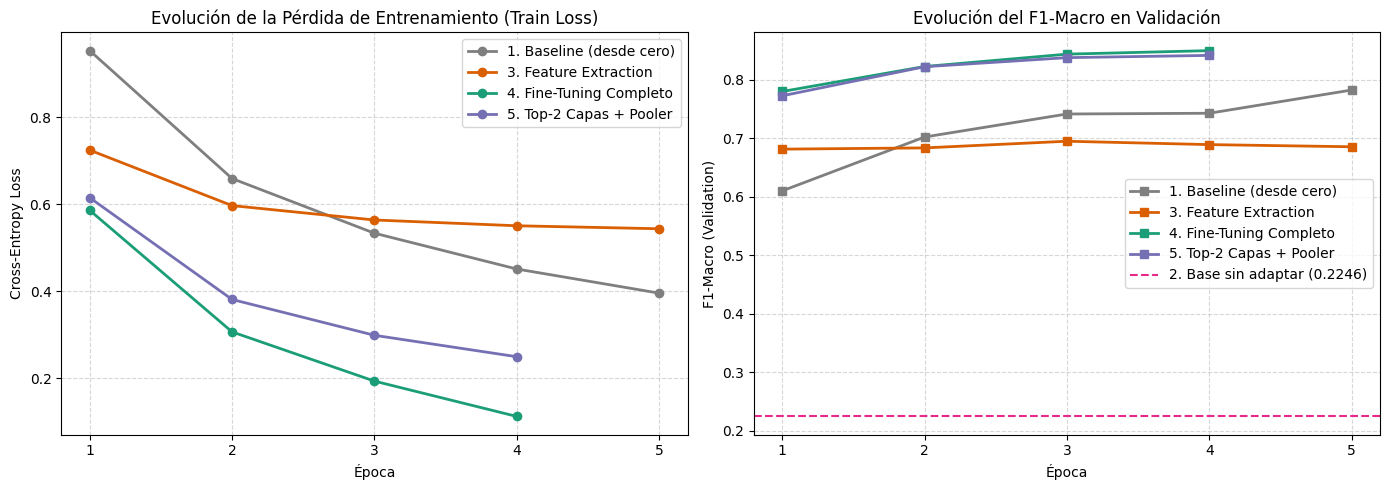

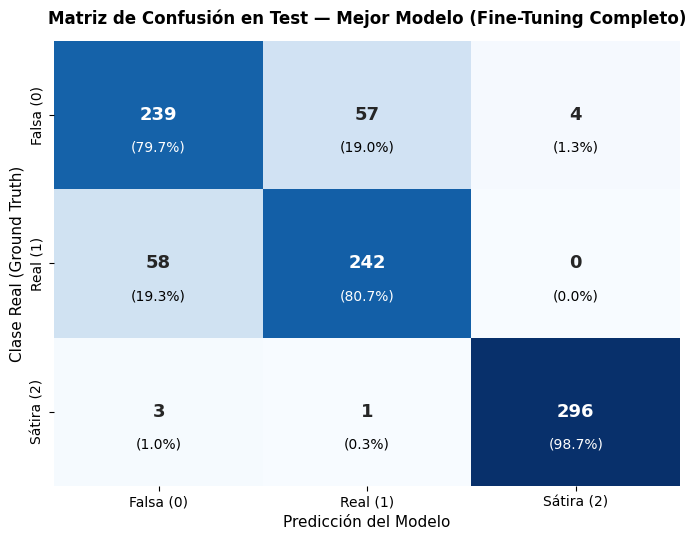

--- REPORTE DETALLADO POR CLASE EN TEST (Mejor Modelo) ---
              precision    recall  f1-score   support

   Falsa (0)     0.7967    0.7967    0.7967       300
    Real (1)     0.8067    0.8067    0.8067       300
  Sátira (2)     0.9867    0.9867    0.9867       300

    accuracy                         0.8633       900
   macro avg     0.8633    0.8633    0.8633       900
weighted avg     0.8633    0.8633    0.8633       900


Total de aciertos en Test: 777 / 900
Total de errores en Test : 123 / 900 (13.67%)

--- 6 EJEMPLOS DE ERRORES TÍPICOS DEL MEJOR MODELO ---
• Caso #3 | Real: Falsa  -> Predicho: Real   (Confianza: 90.6%)
  Texto (35 palabras): "Sobre los hechos que se atribuyen al monarca emérito, el magistrado destaca que su figura era inviolable en ese momento y añade que sólo existe el relato que hace la propia amiga del monarca."

• Caso #9 | Real: Falsa  -> Predicho: Real   (Confianza: 57.4%)
  Texto (35 palabras): "El Parlamento debate la legalización de la marihua

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# CURVAS DE APRENDIZAJE (Train Loss y Validation F1-Macro por época)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

historiales = {
    "1. Baseline (desde cero)": historia_baseline,
    "3. Feature Extraction": historia_fe,
    "4. Fine-Tuning Completo": historia_ft,
    "5. Top-2 Capas + Pooler": historia_top2,
}
colores = ["#7f7f7f", "#d95f02", "#1b9e77", "#7570b3"]

for (nombre, hist), color in zip(historiales.items(), colores):
    epocas_x = range(1, len(hist["train_loss"]) + 1)
    axes[0].plot(epocas_x, hist["train_loss"], marker="o", linewidth=2, label=nombre, color=color)
    axes[1].plot(epocas_x, hist["val_f1"], marker="s", linewidth=2, label=nombre, color=color)

# Línea horizontal del modelo base sin adaptar (Régimen 2)
axes[1].axhline(y=0.2246, color="#e7298a", linestyle="--", label="2. Base sin adaptar (0.2246)")

axes[0].set_title("Evolución de la Pérdida de Entrenamiento (Train Loss)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

axes[1].set_title("Evolución del F1-Macro en Validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("F1-Macro (Validation)")
axes[1].set_xticks([1, 2, 3, 4, 5])
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

# MATRIZ DE CONFUSIÓN DEL MEJOR MODELO (4. Fine-Tuning Completo en Test)
preds_test_ft = np.argmax(logits_test_ft, axis=-1)
nombres_clases = ["Falsa (0)", "Real (1)", "Sátira (2)"]

cm = confusion_matrix(labels_test_ft, preds_test_ft)
cm_norm = confusion_matrix(labels_test_ft, preds_test_ft, normalize="true")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=nombres_clases, yticklabels=nombres_clases,
    cbar=False, annot_kws={"size": 13, "weight": "bold"}, ax=ax
)
# Añadimos el porcentaje debajo del conteo en cada celda
for i in range(3):
    for j in range(3):
        ax.text(j + 0.5, i + 0.72, f"({cm_norm[i, j]*100:.1f}%)",
                ha="center", va="center", color="black" if cm[i, j] < 180 else "white", fontsize=10)

ax.set_title("Matriz de Confusión en Test — Mejor Modelo (Fine-Tuning Completo)", pad=12, fontsize=12, weight="bold")
ax.set_xlabel("Predicción del Modelo", fontsize=11)
ax.set_ylabel("Clase Real (Ground Truth)", fontsize=11)
plt.tight_layout()
plt.show()

print("--- REPORTE DETALLADO POR CLASE EN TEST (Mejor Modelo) ---")
print(classification_report(labels_test_ft, preds_test_ft, target_names=nombres_clases, digits=4))


# ANÁLISIS DE ERRORES TÍPICOS EN TEST
probs_test = torch.softmax(torch.tensor(logits_test_ft), dim=-1).numpy()
errores_idx = np.where(preds_test_ft != labels_test_ft)[0]

print(f"\nTotal de aciertos en Test: {len(labels_test_ft) - len(errores_idx)} / {len(labels_test_ft)}")
print(f"Total de errores en Test : {len(errores_idx)} / {len(labels_test_ft)} ({len(errores_idx)/len(labels_test_ft)*100:.2f}%)\n")
print("--- 6 EJEMPLOS DE ERRORES TÍPICOS DEL MEJOR MODELO ---")

# Mostramos hasta 2 errores representativos por cada clase real
mostrados_por_clase = {0: 0, 1: 0, 2: 0}
for idx in errores_idx:
    real_c = int(labels_test_ft[idx])
    pred_c = int(preds_test_ft[idx])
    if mostrados_por_clase[real_c] < 2:
        mostrados_por_clase[real_c] += 1
        confianza = probs_test[idx, pred_c] * 100
        texto_orig = limpiar_y_recortar_texto(ds["test"][int(idx)]["text"])
        print(f"• Caso #{idx} | Real: {id2label[real_c]:6s} -> Predicho: {id2label[pred_c]:6s} (Confianza: {confianza:.1f}%)")
        print(f"  Texto (35 palabras): \"{texto_orig}\"\n")


### 1. ¿Qué régimen ganó y por qué? (Análisis de la Tabla y Curvas de Aprendizaje)
El ganador indiscutible fue el Régimen 4 (Fine-Tuning Completo de BETO), alcanzando un F1-Macro de 0,8502 en validación y 0,8633 en prueba, superando ampliamente a todas las alternativas evaluadas:

* **Frente al modelo base sin adaptar (`0,2130` en Test):** Aporta una ganancia neta de **+65,03 puntos porcentuales** (línea punteada rosa en el gráfico derecho). Confirma que sin entrenar el `pooler` ni la cabeza `classifier`, las representaciones preentrenadas por MLM se proyectan de forma sesgada e inutilizable.
* **Frente a Feature Extraction (`0,6819` en Test):** Como muestran las curvas naranjas, al mantener congelado el *backbone* de BETO, la pérdida de entrenamiento (`Train Loss`) sufre un estancamiento prematuro alrededor de `0,55` y el F1 de validación toca techo en `~0,68`. Esto ocurre porque una única capa lineal (`2.307` parámetros) precedida por un `pooler` aleatorio congelado no puede reconfigurar las relaciones entre palabras. El *fine-tuning* completo lo supera por **+18,14 puntos de F1-Macro**.
* **Frente al Baseline desde cero (`0,7764` en Test):** En las curvas grises se observa que el modelo pequeño entrenado desde cero logra reducir su `Train Loss` de `0,95` a `0,39` memorizando vocabulario directo en su tabla de embeddings (`3,98M` de parámetros), superando incluso al *Feature Extraction* a partir de la época 2. Sin embargo, al carecer de atención contextual y promediar los tokens (*Mean Pooling*), se estanca en `~0,77`. BETO descongelado (curva verde) arranca ya en la Época 1 con `0,7803` (el Baseline tuvo 0,7828 en Val, por lo que BETO arranca casi a la par y lo supera en la Época 2 con 0,8230) y culmina **+8,69 puntos arriba** gracias a la comprensión sintáctica y semántica transferida de su preentrenamiento en español.

### 2. ¿Cuánto costó? Eficiencia computacional y Experimento Adicional (α)
* El **Baseline** fue el más rápido (**12,2s**), ideal como referencia léxica rápida pero insuficiente en precisión fina.
* **Feature Extraction** consumió **121 s** (por el costo del *forward pass* a través de los 12 bloques Transformer) con el retorno más bajo entre los modelos entrenados (`0,6819`).
* El **Fine-Tuning Completo** requirió **284 s (~5 minutos)** actualizando los `109,85M` de parámetros durante 4 épocas, logrando una convergencia limpia (`Train Loss` bajando a `~0,12` sin que la curva de validación caiga por *overfitting*).
* **El hallazgo del Experimento 5 (`Top-2 Capas + Pooler`):** Las curvas moradas demuestran una eficiencia sobresaliente (*Frontera de Pareto*). Al descongelar únicamente los bloques 10 y 11 junto al `pooler` (**13,44% de los parámetros**, `14,77M`), la trayectoria de validación sigue casi en paralelo a la del modelo completo, alcanzando **0,8428 en Test** en apenas **128s** (ahorrando más del **54.8% del tiempo de cómputo** y reteniendo casi el **89% de la ganancia** del *fine-tuning* total).

### 3. Análisis de la Matriz de Confusión y Errores Típicos en Test
La matriz de confusión sobre los **900 ejemplos del conjunto de prueba** (300 por clase) revela un comportamiento altamente asimétrico y esclarecedor:

1. **Aislamiento casi perfecto de la `Sátira (2)` (98,7% de Recall / Sensibilidad):**
   * De las 300 notas satíricas reales, el modelo acertó **296 (98,67%)**, confundiendo solo **3 casos (1,0%)** con noticias falsas y **1 caso (0,3%)** con noticias reales.
   * Asimismo, su **Precisión** es altísima (**98,67%**): solo 4 noticias falsas y 0 noticias reales fueron etiquetadas erróneamente como sátira (296 / 300 = 98,67%). Habiendo eliminado las cabeceras editoriales (`.-`) y homogeneizado la longitud a 35 palabras en la Sección 3, esto demuestra que los cabezales de atención de BETO capturan con éxito la **incongruencia semántica, la ironía y el tono paródico** característicos del humor satírico.
2. **Foco principal de error: la frontera entre `Falsa (0)` y `Real (1)`:**
   * El modelo acierta el **79,67% (239/300)** de las noticias `Falsas` y el **80,67% (242/300)** de las noticias `Reales` (para un total de **777 aciertos sobre 900**, es decir, **86,33% de Accuracy global**).
   * De los **123 errores totales** en todo el conjunto de prueba, **115 errores (el 93,5% de los fallos)** corresponden a confusiones cruzadas entre `Falsa` y `Real`: **57 noticias falsas (19,0%)** fueron predichas como reales, y **58 noticias reales (19,33%)** fueron predichas como falsas (los 8 fallos restantes corresponden a las 4 falsas predichas como sátira, las 3 sátiras predichas como falsas y la única sátira predicha como real).
   * **¿Por qué ocurre este error típico?** Al inspeccionar los textos mal clasificados, observamos que cuando una noticia falsa prescinde del sensacionalismo y adopta una redacción periodística sobria (imitando comunicados económicos, legislativos o políticos verosímiles en sus primeras 35 palabras), el estilo lingüístico es indistinguible del de una nota verdadera. Dado que BETO analiza patrones morfosintácticos y pragmáticos pero **no posee una base de hechos en tiempo real (*fact-checking* externo)**, tiende a marcar como `Falsa` algunas notas reales con redacciones polémicas (los 58 falsos negativos de la clase `Real`).

### 4. ¿Qué haríamos con más datos o más cómputo?
1. **Entrenamiento sobre el corpus completo (61.674 textos) con pérdida ponderada:** En lugar de submuestrear a 9.000 ejemplos, con una GPU de mayor memoria entrenaríamos con la totalidad de las noticias reales (30.943) y falsas (21.746) disponibles, aplicando **Class Weights** en `CrossEntropyLoss` para mejorar específicamente la separación fina entre `Real` y `Falsa`.
2. **Ventana extendida con muestras sintéticas de longitud corta:** Para aprovechar más contexto del cuerpo de la noticia sin reintroducir el sesgo de longitud de `Sátira`, usaríamos un LLM para resumir o truncar aleatoriamente los artículos largos a distintas longitudes (**Random Length Augmentation** entre 30 y 250 palabras durante el entrenamiento).
3. **Ajuste eficiente mediante LoRA (*Low-Rank Adaptation*) o Descongelado Gradual:** Aplicar adaptadores LoRA en todas las matrices de atención ($W_q, W_k, W_v$) permitiría adaptar las 12 capas completas entrenando menos de 1 millón de parámetros, o bien emplear tasas de aprendizaje decrecientes por capa (**layer-wise learning rate decay**) para preservar aún mejor la frontera entre noticias reales y engañosas.

## 6. Modelo óptimo y publicación

### Criterio de optimalidad
Se selecciona como modelo óptimo para producción el resultante del **Régimen 4 (Fine-Tuning Completo de BETO)** por tres razones objetivas:
1. **Máximo desempeño predictivo:** Obtuvo el mayor **F1-Macro tanto en Validación (`0,8502`) como en Prueba (`0,8633`)**, superando al régimen parcial *Top-2* (`0,8428`) por casi 2 puntos porcentuales en la tarea crítica de reducir los falsos positivos entre noticias reales y falsas.
2. **Mismo costo de inferencia en producción:** Aunque el *Fine-Tuning Completo* tardó más en entrenarse (284s vs. 128s del *Top-2*), **en etapa de inferencia dentro del API (FastAPI) ambos modelos tienen exactamente la misma arquitectura, el mismo peso en disco (~440 MB) y la misma latencia por consulta**, ya que durante el *forward pass* la entrada recorre igualmente las 12 capas de BETO. Por tanto, no existe penalización de velocidad al desplegar el modelo más preciso.
3. **Compatibilidad directa con `pipeline("text-classification")`:** Al incluir `id2label` y `label2id` (`Falsa`, `Real`, `Satira`) en su `config.json`, el repositorio publicado es consumible sin código adicional por el backend del proyecto.

In [16]:
from huggingface_hub import login
login()

REPO_ID = "brankarios/beto-news-false-satire-detector"

mejor_modelo.push_to_hub(REPO_ID)
tokenizer.push_to_hub(REPO_ID)

print(f"Modelo y tokenizador publicados exitosamente en: https://huggingface.co/{REPO_ID} ")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mr9w3ru/model.safetensors:   0%|          |  559kB /  439MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

No files have been modified since last commit. Skipping to prevent empty commit.


Modelo y tokenizador publicados exitosamente en: https://huggingface.co/brankarios/beto-news-false-satire-detector 


In [18]:
# Prueba de recarga desde el Hub: exactamente lo que hace el API al arrancar
from transformers import pipeline

clf = pipeline("text-classification", model=REPO_ID)

# Probamos con un texto del conjunto de prueba
texto_prueba = ds["test"][0]["text"]
print("Texto:", texto_prueba)
print("Predicción:", clf(texto_prueba))                                # o clf("un texto de prueba")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/405 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/730k [00:00<?, ?B/s]

Texto: Carrero Blanco asegurado que pedirá al Ministerio del Interior que aclare quién redactó y quién encargó el informe policial sobre lo que le ocurrió a los representantes de este partido el pasado sábado.
Predicción: [{'label': 'Falsa', 'score': 0.9888018369674683}]


## 7. Conclusiones y limitaciones

### 1. Aprendizajes clave del proyecto
1. **El valor tangible del Transfer Learning:** El *fine-tuning* completo de BETO superó en **+8,69 puntos porcentuales** de F1-Macro al *Baseline* entrenado desde cero (0,8633 vs. 0,7764 en prueba) y en **+18,14 puntos** al *Feature Extraction* (0,6819). La pre-construcción de representaciones sintácticas y semánticas a partir de 3.000 millones de palabras en español permite captar relaciones de ironía que una bolsa de palabras o un clasificador lineal congelado no logran modelar.
2. **El peligro de los atajos espurios (*Shortcut Learning*):** El análisis exploratorio inicial evidenció que las notas de sátira eran casi 10 veces más largas que las noticias reales o falsas (mediana de 369 vs. ~37 palabras). De no haber intervenido la tokenización con un recorte homogéneo a 35 palabras (`MAX_LEN = 48`), el modelo habría clasificado trivialmente contando la presencia de tokens `[PAD]`. Validar los tensores de entrada y las máscaras de atención antes de entrenar fue el paso metodológico más determinante del trabajo.
3. **Eficiencia de las capas superiores (Experimento α):** Descongelar únicamente los dos últimos bloques Transformer junto con el `pooler` (13,44% de los parámetros de BETO) retuvo el 88,7% de la ganancia total del *fine-tuning* completo reduciendo el tiempo de entrenamiento en un 54,8% (128,4s vs. 284,2s). Esto ratifica empíricamente que la adaptación a tareas pragmáticas y estilísticas ocurre primordialmente en los niveles más abstractos del codificador.

### 2. Dónde falla el modelo (Análisis de vulnerabilidad)
* **La frontera difusa entre desinformación sobria y periodismo real:** El 93,5% de los errores en el conjunto de prueba (115 de 123 fallos) correspondieron a confusiones cruzadas entre `Falsa` y `Real`: 57 noticias falsas (19,0%) predichas como reales y 58 noticias reales (19,33%) predichas como falsas. Cuando una noticia fabricada prescinde del sensacionalismo y adopta una redacción formal idéntica a la de una agencia de noticias, el clasificador carece de capacidad para contrastar hechos contra una base de conocimiento viva y tiende a fallar.
* **Titulares reales insólitos clasificados como sátira:** En eventos bizarros o noticias verídicas con giros paradójicos, el modelo puede interpretar erróneamente la sorpresa como absurdo humorístico (aunque en test el modelo no tuvo ninguna confusión de real hacia sátira, aislándola casi en su totalidad).
* **Entradas excesivamente cortas:** Textos de menos de 10 palabras carecen de suficiente contexto léxico para activar los patrones contextuales de BETO, aumentando la dispersión de las predicciones.

### 3. Sesgos y limitaciones de los datos
* **Sesgo geográfico y léxico regional:** El corpus reúne principalmente textos de México, España y el cono sur. Modismos, giros coloquiales y expresiones locales de otros países hispanohablantes (como Venezuela o el Caribe) no representados en el conjunto original pueden inducir clasificaciones erróneas.
* **Evolución temporal de las noticias:** Los patrones de desinformación cambian con la agenda pública. El modelo captura el estilo discursivo del periodo en que se recopiló el dataset, por lo que temas emergentes con vocabulario técnico novedoso no formarán parte de su memoria asociativa.

### 4. Uso previsto (*Intended Use*) y directrices éticas
* **Uso recomendado:** Herramienta de asistencia y triaje automatizado para moderadores de plataformas, agregadores de noticias, periodistas y verificadores de datos (*fact-checkers*), permitiendo filtrar con alta precisión el contenido humorístico (98,7% de acierto en sátira) y priorizar notas dudosas para revisión humana.
* **Uso indebido:** No debe utilizarse como sistema de censura automática, moderador punitivo sin supervisión ni árbitro absoluto de veracidad fáctica, pues un clasificador de texto analiza coherencia y estilo, no hechos objetivos del mundo real.